# Summary

This analysis explores transactional data from an online retail business to identify revenue drivers, customer behavior, and product performance.

# 0. Setup and Load Data

In [1]:
import os
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt


conn = sqlite3.connect("../retail.db")

In [2]:
pd.read_sql(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

,name
0,retail
1,retail_clean
2,retail_clean_dedup
3,retail_final
4,customers
5,products
6,sales


### Check if there is duplicates ID

In [3]:
tables_to_check = {
    "customers": ("SELECT * FROM customers;", "customer_id"),
    "products": ("SELECT * FROM products;", "product_id"),
    "sales": ("SELECT * FROM sales;", None),
}

for name, (query, pk) in tables_to_check.items():
    df_check = pd.read_sql(query, conn)
    print(f"--- {name} | rows: {len(df_check)} ---")
    if pk:
        dups = df_check[pk].duplicated().sum()
        nulls = df_check[pk].isna().sum()
        print(f"Duplicates in {pk}: {dups} | Nulls in {pk}: {nulls}")

--- customers | rows: 5878 ---
Duplicates in customer_id: 0 | Nulls in customer_id: 0
--- products | rows: 4631 ---
Duplicates in product_id: 0 | Nulls in product_id: 0
--- sales | rows: 779421 ---


#1 KPI Análisis

## 1.1 TOTAL REVENUE

This metric shows the total revenue generated by the online retail store during the analyzed period.

It helps us understand the overall scale of the business and serves as the baseline for all other KPIs.

In [4]:
query = """
SELECT
ROUND(SUM(quantity * price), 2) AS total_revenue
FROM sales;
"""
print("Total Revenue:", pd.read_sql(query, conn).iloc[0, 0])


Total Revenue: 17374218.82


The total revenue represents the full monetary value generated by all transactions in the dataset.

This KPI is heavily influenced by high-volume orders and repeat customers, indicating that customer retention and order frequency are key drivers of revenue.

# 1.2 TOTAL ORDERS
This KPI shows the total number of unique invoices processed in the dataset.

In [5]:
query = """ 
SELECT
COUNT(DISTINCT invoice) AS total_orders
FROM sales;
"""
print("Total Orders:", pd.read_sql(query, conn).iloc[0, 0])

Total Orders: 36969


The number of orders helps measure business activity and demand frequency.

# 1.3 TOTAL CUSTOMERS
This metric represents the number of unique customers who made at least one purchase.

In [6]:
query = """
SELECT
COUNT(DISTINCT customer_id) AS total_customers
FROM customers;
"""
print("Total Customers:", pd.read_sql(query, conn).iloc[0, 0])

Total Customers: 5878


This KPI reflects the size of the active customer base and is key for understanding market reach.

## 1.4 AVERAGE ORDER VALUE
This metric shows the average revenue generated per order.

In [7]:
query = """
SELECT
ROUND(
SUM(quantity * price) /
COUNT(DISTINCT invoice),
2
) AS average_order_value
FROM sales;
"""
print("Average Order Value:", pd.read_sql(query, conn).iloc[0, 0])

Average Order Value: 469.97


AOV indicates customer spending behavior. A higher value suggests customers are purchasing more per transaction.

# 1.5 REVENUE BY COUNTRY
This KPI breaks down revenue by geographic region.

In [8]:
query = """
SELECT
c.country,
ROUND(SUM(s.quantity * s.price), 2) AS revenue
FROM sales s
JOIN customers c
ON s.customer_id = c.customer_id
GROUP BY c.country
ORDER BY revenue DESC;
"""
df = pd.read_sql(query, conn)
print("Revenue by Country:")
print(df)

Revenue by Country:
                 country      revenue
0         United Kingdom  14387925.62
1                   EIRE    617294.39
2            Netherlands    554038.09
3                Germany    424922.66
4                 France    349107.36
5              Australia    174439.59
6                  Spain    106684.82
7            Switzerland     95035.03
8                 Sweden     91515.82
9                Belgium     65252.55
10               Denmark     60855.46
11                Norway     56322.50
12              Portugal     55554.78
13       Channel Islands     44623.33
14                 Japan     43023.91
15               Austria     32644.18
16                 Italy     32108.17
17               Finland     29925.54
18             Singapore     25317.06
19                Cyprus     24956.38
20                Greece     19096.19
21                Poland     10654.29
22                Israel     10415.24
23  United Arab Emirates      9202.69
24           Unspecified      

Revenue is often concentrated in a few countries, showing geographic dependency of the business.

## 1.6 TOP 10 PRODUCTS BY REVENUE
This shows which products generate the most income.

In [9]:
query = """
SELECT
p.product_name,
ROUND(SUM(s.quantity * s.price), 2) AS revenue
FROM sales s
JOIN products p
ON s.product_id = p.product_id
GROUP BY p.product_name
ORDER BY revenue DESC
LIMIT 10;
"""
df = pd.read_sql(query, conn)
print("Top 10 Products by Revenue:")
print(pd.read_sql(query, conn))

Top 10 Products by Revenue:
                         product_name    revenue
0            REGENCY CAKESTAND 3 TIER  277656.25
1  CREAM HANGING HEART T-LIGHT HOLDER  247203.36
2         PAPER CRAFT , LITTLE BIRDIE  168469.60
3             JUMBO BAG RED RETROSPOT  167920.64
4                              Manual  151777.67
5                             POSTAGE  124648.04
6       ASSORTED COLOUR BIRD ORNAMENT  124351.86
7                       PARTY BUNTING  103283.38
8      MEDIUM CERAMIC TOP STORAGE JAR   81416.73
9     PAPER CHAIN KIT 50'S CHRISTMAS    76598.18


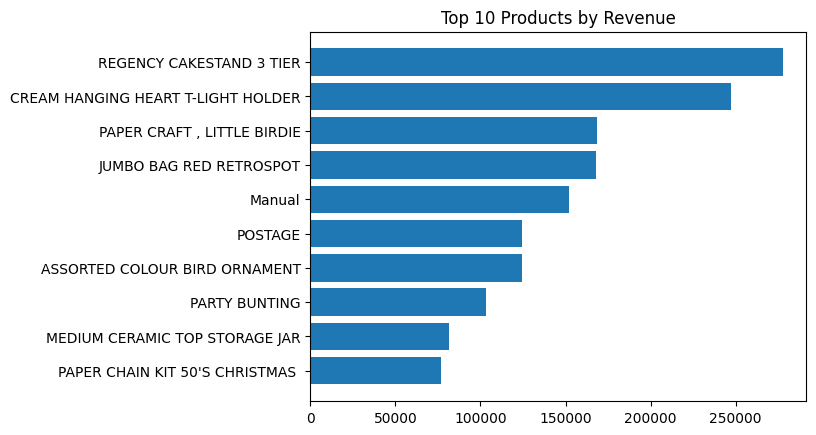

In [10]:
plt.figure()
plt.barh(df["product_name"], df["revenue"])
plt.title("Top 10 Products by Revenue")
plt.gca().invert_yaxis()
plt.show()

A small number of products often contribute disproportionately to total revenue (Pareto effect).

## 1.7 MONTHLY REVENUE TREND


This KPI shows how revenue evolves over time.

In [11]:
query = """
SELECT
strftime('%Y-%m', sale_date) AS month,
ROUND(SUM(quantity * price), 2) AS revenue
FROM sales
GROUP BY month
ORDER BY month;
"""
df=pd.read_sql(query, conn)
print("Monthly Revenue Trend:")
print(df)

Monthly Revenue Trend:
      month     revenue
0   2009-12   683474.31
1   2010-01   555802.67
2   2010-02   504558.96
3   2010-03   696978.47
4   2010-04   591982.00
5   2010-05   597833.38
6   2010-06   636371.13
7   2010-07   589736.17
8   2010-08   602224.60
9   2010-09   829013.95
10  2010-10  1033112.01
11  2010-11  1166460.02
12  2010-12   570422.73
13  2011-01   568101.31
14  2011-02   446084.92
15  2011-03   594081.76
16  2011-04   468374.33
17  2011-05   677340.30
18  2011-06   660046.05
19  2011-07   598962.90
20  2011-08   644051.04
21  2011-09   950686.30
22  2011-10  1035642.45
23  2011-11  1155668.61
24  2011-12   517208.44


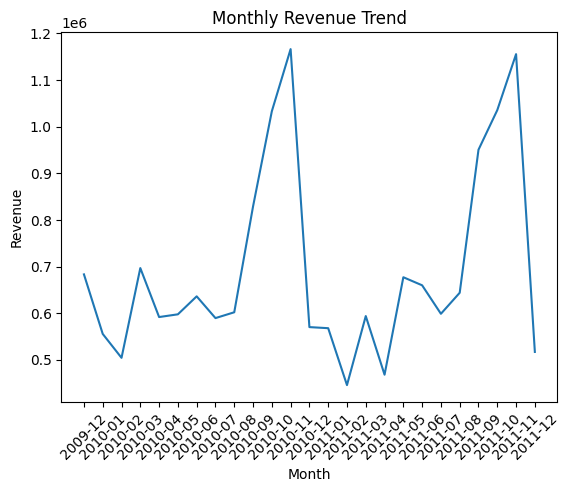

In [12]:
plt.figure()
plt.plot(df["month"], df["revenue"])
plt.xticks(rotation=45)
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.show()

Revenue trends help identify seasonality, growth patterns, and demand fluctuations.

## 1.8 BEST CUSTOMERS BY SPENDING
This metric identifies the highest-value customers.

In [13]:
query = """
SELECT
customer_id,
ROUND(SUM(quantity * price), 2) AS total_spent
FROM sales
GROUP BY customer_id
ORDER BY total_spent DESC
LIMIT 10;
"""
df = pd.read_sql(query, conn)
print("Best Customers by Spending:")
print(df)


Best Customers by Spending:
   customer_id  total_spent
0        18102    580987.04
1        14646    528602.52
2        14156    313437.62
3        14911    291420.81
4        17450    244784.25
5        13694    195640.69
6        17511    172132.87
7        16446    168472.50
8        16684    147142.77
9        12415    144458.37


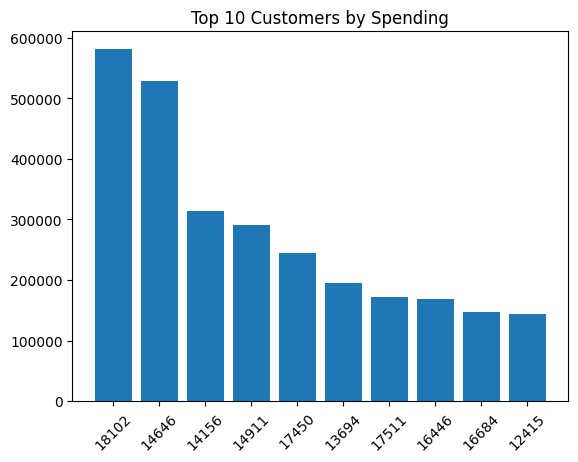

In [14]:
plt.figure()
plt.bar(df["customer_id"].astype(str), df["total_spent"])
plt.title("Top 10 Customers by Spending")
plt.xticks(rotation=45)
plt.show()

A small group of customers typically drives a large share of total revenue (VIP effect).

# 2 Ranking Analysis

This section analyzes the distribution of revenue across customers and products using ranking techniques.

## 2.1 Top customers ranked by total spend

This section identifies the most valuable customers based on total spending.

We use aggregation to calculate total revenue per customer and apply a ranking function to order them from highest to lowest.

In [15]:
query = """
SELECT
    customer_id,
    total_spent,
    RANK() OVER (ORDER BY total_spent DESC) AS rank_position
FROM (
    SELECT
        customer_id,
        SUM(quantity * price) AS total_spent
    FROM sales
    GROUP BY customer_id
);
"""
df = pd.read_sql(query, conn)
print("Customers with Rank:")
print(df)

Customers with Rank:
      customer_id  total_spent  rank_position
0           18102    580987.04              1
1           14646    528602.52              2
2           14156    313437.62              3
3           14911    291420.81              4
4           17450    244784.25              5
...           ...          ...            ...
5873        15913         6.30           5874
5874        14792         6.20           5875
5875        13788         3.75           5876
5876        16738         3.75           5876
5877        14095         2.95           5878

[5878 rows x 3 columns]


Revenue is highly concentrated among a small group of customers.

This suggests a strong dependency on high-value customers, which is typical in retail datasets and aligns with the Pareto principle (80/20 rule).

## 2.2 top products ranked

This analysis identifies which products generate the highest total revenue.

We aggregate sales at product level to evaluate performance across the catalogue.

In [16]:
query = """ 
SELECT
    product_id,
    total_revenue,
    RANK() OVER (ORDER BY total_revenue DESC) AS rank_position
FROM (
    SELECT
        product_id,
        SUM(quantity * price) AS total_revenue
    FROM sales
    GROUP BY product_id
);
"""
df = pd.read_sql(query, conn)   
print("Products with Dense Rank:")
print(df)

Products with Dense Rank:
     product_id  total_revenue  rank_position
0         22423     277656.250              1
1        85123A     247203.360              2
2         23843     168469.600              3
3        85099B     167920.640              4
4             M     151777.670              5
...         ...            ...            ...
4626    TEST002          1.000           4627
4627      20721          0.850           4628
4628      35930          0.380           4629
4629     84205C          0.380           4629
4630       PADS          0.017           4631

[4631 rows x 3 columns]


A small subset of products generates a disproportionately large share of revenue.

This indicates that product demand is highly concentrated and suggests prioritizing inventory and marketing for these items.

## 2.3 Product Ranking Distribution (Dense Rank)

This section uses DENSE_RANK to group products with similar revenue levels.

It helps identify clusters of product performance rather than strict o

In [17]:
query = """
SELECT
    product_id,
    total_revenue,
    DENSE_RANK() OVER (ORDER BY total_revenue DESC) AS dense_rank_position
FROM (
    SELECT
        product_id,
        SUM(quantity * price) AS total_revenue
    FROM sales
    GROUP BY product_id
);
"""
df = pd.read_sql(query, conn)
print("Products with Dense Rank:")
print(df)


Products with Dense Rank:
     product_id  total_revenue  dense_rank_position
0         22423     277656.250                    1
1        85123A     247203.360                    2
2         23843     168469.600                    3
3        85099B     167920.640                    4
4             M     151777.670                    5
...         ...            ...                  ...
4626    TEST002          1.000                 4309
4627      20721          0.850                 4310
4628      35930          0.380                 4311
4629     84205C          0.380                 4311
4630       PADS          0.017                 4312

[4631 rows x 3 columns]


Products tend to form revenue clusters rather than a smooth distribution.

This suggests that pricing, demand, or popularity effects create natural groupings in product performance.

## 2.4 Top 10 products by revenue
This query highlights the top 10 best-performing products in terms of total revenue.

In [18]:
query = """
SELECT
    product_id,
    total_revenue
FROM (
    SELECT
        product_id,
        SUM(quantity * price) AS total_revenue
    FROM sales
    GROUP BY product_id
)
ORDER BY total_revenue DESC
LIMIT 10;
"""
df = pd.read_sql(query, conn)
print("Top 10 Products by Revenue:")
print(df)

Top 10 Products by Revenue:
  product_id  total_revenue
0      22423      277656.25
1     85123A      247203.36
2      23843      168469.60
3     85099B      167920.64
4          M      151777.67
5       POST      124648.04
6      84879      124351.86
7      47566      103283.38
8      23166       81416.73
9      22086       76598.18


The top 10 products contribute significantly to overall revenue, reinforcing the importance of focusing on best-selling items for business strategy.

## 2.5 Percentage contribution of each customer to total revenue
This analysis calculates the percentage contribution of each customer to total revenue.

It helps identify how concentrated revenue is across the customer base.

In [19]:
query = """
WITH customer_revenue AS (
    SELECT
        customer_id,
        SUM(quantity * price) AS total_spent
    FROM sales
    GROUP BY customer_id
)

SELECT
    customer_id,
    total_spent,
    ROUND(
        100.0 * total_spent / SUM(total_spent) OVER(),
        2
    ) AS revenue_percentage
FROM customer_revenue
ORDER BY total_spent DESC;
"""
df = pd.read_sql(query, conn)
print("Customer Revenue Percentage:")
print(df)

Customer Revenue Percentage:
      customer_id  total_spent  revenue_percentage
0           18102    580987.04                3.34
1           14646    528602.52                3.04
2           14156    313437.62                1.80
3           14911    291420.81                1.68
4           17450    244784.25                1.41
...           ...          ...                 ...
5873        15913         6.30                0.00
5874        14792         6.20                0.00
5875        13788         3.75                0.00
5876        16738         3.75                0.00
5877        14095         2.95                0.00

[5878 rows x 3 columns]


A small number of customers contribute a large share of total revenue.

This highlights the importance of customer retention strategies and VIP customer management.

# Final Conclusions

- The business generates significant revenue from a relatively small group of high-value customers.
- Revenue is strongly concentrated in a limited number of products, suggesting a Pareto-like distribution.
- Monthly revenue trends show fluctuations over time, indicating possible seasonality effects.
- Ranking analysis highlights the importance of top-performing customers and products in overall business performance.
- SQL-based analysis proved effective for transforming raw transactional data into actionable business insights.

# Export clear data from sql to csv

In [20]:
# Create folder for processed data
os.makedirs("../data/processed", exist_ok=True)

conn = sqlite3.connect("../retail.db")

# Export the 3 tables from the relational model
for table in ["customers", "products", "sales"]:
    df = pd.read_sql(f"SELECT * FROM {table}", conn)
    df.to_csv(f"../data/processed/{table}.csv", index=False)

conn.close()
print("Tablas exportadas correctamente a data/processed/")

Tablas exportadas correctamente a data/processed/
